# Predicción de Pokémon legendarios

## Definición del problema
- **Target:** `is_legendary` (1 = legendario, 0 = no legendario)
- **Tipo de problema:** clasificación binaria
- **Features:** stats de combate (hp, attack, defense, sp_attack, sp_defense, speed), altura, peso, generación, base_happiness y tipos (codificados como dummies).
- **¿Por qué los datos podrían servir?** En el EDA de la Tarea 1 observamos que los legendarios tienen stats de combate considerablemente más altos que el resto. Además, la mayoría de los no legendarios tiene base_happiness = 70, mientras que los legendarios suelen tener valores distintos. Esto sugiere que las features contienen información crucial que separa ambas clases.
- **Algoritmo:** Random Forest (bagging). Lo elegimos porque captura relaciones no lineales entre features, un legendario se caracteriza por tener varios stats altos a la vez, no necesita escalar los datos, acepta NaN de forma nativa y, al promediar muchos árboles entrenados con muestras bootstrap distintas, reduce el sobreajuste que tendría un árbol de decisión individual.

In [ ]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd

pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_colwidth', 100)


font = {'size'   : 16}
matplotlib.rc('font', **font)
matplotlib.rc('xtick', labelsize=14)    
matplotlib.rc('ytick', labelsize=14) 
matplotlib.rcParams.update({'figure.autolayout': False})
matplotlib.rcParams['figure.dpi'] = 300

In [34]:
PokemonSet = pd.read_csv('pokemon.csv')
target = PokemonSet['is_legendary']

In [35]:
PokemonSet['capture_rate'] = pd.to_numeric(PokemonSet['capture_rate'], errors='coerce')

PokemonSet['capture_rate'] = (
    PokemonSet['capture_rate']
    .astype(str)
    .str.extract(r'(\d+)', expand=False)
    .astype('Int64')
)

## Filtrado de Features

Para que el algoritmo realice un mejor trabajo, filtramos los features que tiene el DataSet. En este caso eliminamos los siguientes features que no aportan información relevante (según criterio propio):
- name
- japanese_name
- pokedex_number
- classification
- against_? 

Además, debido a que abilities es un string que contiene una o más habilidades por pokemones, es una feature un poco más difícil de trabajar, por lo que optamos por eliminarla del DataSet:
- abilities

También eliminamos el feature que nos dice directamente si el pokemon es legendario (pero se utilizará para validar los resultados, por eso se guardo la variable 'y' antes):
- is_legendary

Eliminamos los siguientes 5 features debido a que en el trabajo anterior se determinó que estas están directamente relacionadas con los pokemones legendarios (concentran a los legendarios dentro de unos rangos pequeños), creando así un mejor desafío con el modelo para determinar si es que se puede predecir correctamente utilizando las demás features:
- capture_rate
- percentage_male
- base_egg_steps 
- experience_growth
- base_total

En un anexo al final del notebook se demuestra que estas features generan un modelo que logra predecir de forma perfecta los pokemones legendarios, por lo que para probar mejor distintas formas de trabajar este DataSet se restringen las features dominantes, dejando únicamente base_happiness como otra feature dominante posible a eliminar, pero que no resulta tan influyente como el resto.

In [36]:
PokemonSet = PokemonSet.drop(['name', 
                            'japanese_name', 
                            'pokedex_number',
                            'classfication',
                            'against_fire',
                            'against_water',
                            'against_electric',
                            'against_grass',
                            'against_ice',
                            'against_fight',
                            'against_poison',
                            'against_ground',
                            'against_flying',
                            'against_psychic',
                            'against_bug',
                            'against_rock',
                            'against_ghost',
                            'against_dragon',
                            'against_dark',
                            'against_steel',
                            'against_fairy',
                            'against_normal',
                            'is_legendary',
                            'abilities'],
                            axis=1)

PokemonSetF = PokemonSet.drop(['capture_rate',
                               'percentage_male',
                               'base_egg_steps',
                               'experience_growth',
                               'base_total'],
                               axis=1)

PokemonSetF

,attack,base_happiness,defense,height_m,hp,sp_attack,sp_defense,speed,type1,type2,weight_kg,generation
0,49,70,49,0.7,45,65,65,45,grass,poison,6.9,1
1,62,70,63,1.0,60,80,80,60,grass,poison,13.0,1
2,100,70,123,2.0,80,122,120,80,grass,poison,100.0,1
3,52,70,43,0.6,39,60,50,65,fire,NaN,8.5,1
4,64,70,58,1.1,58,80,65,80,fire,NaN,19.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
796,101,0,103,9.2,97,107,101,61,steel,flying,999.9,7
797,181,0,131,0.3,59,59,31,109,grass,steel,0.1,7
798,101,0,53,5.5,223,97,53,43,dark,dragon,888.0,7
799,107,0,101,2.4,97,127,89,79,psychic,NaN,230.0,7


Las variables que corresponden a características cualitativas deben de convertirse en valores numéricos para poder ser analizados, así que convertimos las variables 'type1' y 'type2' en una matriz que represente con '1' al tipo de pokemon que si corresponde, y '0' al tipo que no (de esta forma eliminamos los NaN's de la tabla de datos).

In [ ]:
tipos = (pd.get_dummies(PokemonSetF['type1'], dtype=int)
           .add(pd.get_dummies(PokemonSetF['type2'], dtype=int), fill_value=0)
           .astype(int)
           .add_prefix('tipo_'))


PokemonSetF = pd.concat([PokemonSetF.drop(columns=['type1', 'type2']), tipos], axis=1)

In [38]:
PokemonSetF

,attack,base_happiness,defense,height_m,hp,sp_attack,sp_defense,speed,weight_kg,generation,tipo_bug,tipo_dark,tipo_dragon,tipo_electric,tipo_fairy,tipo_fighting,tipo_fire,tipo_flying,tipo_ghost,tipo_grass,tipo_ground,tipo_ice,tipo_normal,tipo_poison,tipo_psychic,tipo_rock,tipo_steel,tipo_water
0,49,70,49,0.7,45,65,65,45,6.9,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0
1,62,70,63,1.0,60,80,80,60,13.0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0
2,100,70,123,2.0,80,122,120,80,100.0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0
3,52,70,43,0.6,39,60,50,65,8.5,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0
4,64,70,58,1.1,58,80,65,80,19.0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
796,101,0,103,9.2,97,107,101,61,999.9,7,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0
797,181,0,131,0.3,59,59,31,109,0.1,7,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0
798,101,0,53,5.5,223,97,53,43,888.0,7,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
799,107,0,101,2.4,97,127,89,79,230.0,7,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0


En el caso de los NaN's que se obtienen en la altura y peso, los dejaremos tal cual como están, pues aunque ya sabemos del EDA que este es un error del DataSet debido a que mezcla las características de un pokemon original con alguna variación suya, no queremos modificar mucho los datos que recibimos. De esta manera nos ajustamos mejor a un caso realista en el que podría haber también un error en los datos recolectados.

## Features y Target

De forma final nuestro Target es la predicción de pokemon legendarios y=is_legendary, determinada como '0' para pokemones no legendarios, y como '1' para pokemones legendarios (problema de clasificación con '1' caso verdadero).

Las características que se utilizarán de forma final para la predicción de los pokemones legendarios son las siguientes:

- Stats básicos: attack, defense, hp, sp_attack, sp_defense, speed
- Características únicas: base_happiness, height_m, weight_kg, generación, tipos

La idea de utilizar estos datos es comprobar si los stats y otras características propias y simples de los pokemones son suficientes para determinar si este es legendario o no.

# Parte 1: Construcción de un modelo

## Algoritmo seleccionado

Para evaluar este DataSet filtrado se utilizará un modelo de RandomForest de clasificación, de forma que nos podamos ajustar mejor al desbalance de clases (70 pokemones legendarios en un total de 801 pokemones) utilizando trucos de Bagging para aprovechar mejor la información de los pocos legendarios que hay en total.

In [39]:
from sklearn import metrics
from sklearn.model_selection import ParameterGrid
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, precision_score, recall_score

In [40]:
PokemonSetF.shape

(801, 28)

In [41]:
features = PokemonSetF # Como ya filtramos, utilizaremos todas las features actuamente presentes en PokemonSet

Como la cantidad de pokemones legendarios es poca frente al número total de pokemones, en vez de hacer un train_test_split (que generará grupos con aún menor cantidad de legendarios), utilizaremos el error out-of-bag (OOB) de Random Forest. Cada árbol se entrena con una muestra con reemplazo de los datos (bootstrap), por lo que deja fuera aproximadamente un 37% de los pokemones, y cada árbol deja fuera un grupo distinto. De esta forma, cada pokemon es predicho solo por los árboles que no lo vieron durante su entrenamiento.

Este truco permite que todos los pokemones (incluidos los 70 legendarios) sirvan como datos de prueba, sin apartar un conjunto aparte y con un solo entrenamiento por modelo.

**Sobre el data leakage:** las únicas transformaciones aplicadas a los datos (eliminar columnas y codificar los tipos como variables binarias) no aprenden parámetros desde los datos, y no se escala ni elimina ningún valor (los NaN se dejan tal cual y Random Forest no requiere escalado), por lo que no se filtra información entre los datos de entrenamiento y los de prueba. Además, con el OOB cada pokemon es predicho solo por árboles que no lo vieron durante su entrenamiento. La única decisión que sí utiliza todos los datos es la elección de hiperparámetros, cuyo efecto levemente optimista se discute más abajo.

In [42]:
parameters = {'max_features':['sqrt', 4, None],
              'min_samples_split': [2, 5, 10], 
              'min_samples_leaf': [1, 2, 4],
              'class_weight': [None, 'balanced_subsample']}

Como nuestra clase positiva '1' pokemon Legendario es mucho menor que la clase '0' No Legendario, entonces la métrica de accuracy no sería efectiva (un lazy benchmark obtendría un acc de 91.26%). La métrica que usaremos para elegir los hiperparámetros entonces es F1, que equilibra el recall (cantidad de legendarios bien detectados) y la precision (cantidad de predicciones de legendario que son correctas). Igualmente se reportan recall y precision por separado.

In [43]:
criterio = 'f1'

filas = []
for params in ParameterGrid(parameters):
    rf_tmp = RandomForestClassifier(n_estimators=500, oob_score=True,
                                    n_jobs=-1, random_state=42, **params)
    rf_tmp.fit(features, target)
    pred = (rf_tmp.oob_decision_function_[:, 1] > 0.5).astype(int)
    filas.append({**params,
                  'f1': f1_score(target, pred),
                  'precision': precision_score(target, pred),
                  'recall': recall_score(target, pred)})

In [44]:
mejores = max(filas, key=lambda f: f[criterio])
mejores_params = {k: mejores[k] for k in parameters}
print(mejores_params)

{'max_features': None, 'min_samples_split': 2, 'min_samples_leaf': 1, 'class_weight': None}


In [45]:
resultados_oob = pd.DataFrame(filas).sort_values(by=criterio, ascending=False)

In [46]:
resultados_oob

,class_weight,max_features,min_samples_leaf,min_samples_split,f1,precision,recall
18,NaN,None,1,2,0.872180,0.920635,0.828571
19,NaN,None,1,5,0.835821,0.875000,0.800000
20,NaN,None,1,10,0.827068,0.873016,0.785714
26,NaN,None,4,10,0.823529,0.848485,0.800000
21,NaN,None,2,2,0.820896,0.859375,0.785714
23,NaN,None,2,10,0.818182,0.870968,0.771429
22,NaN,None,2,5,0.814815,0.846154,0.785714
24,NaN,None,4,2,0.805970,0.843750,0.771429
25,NaN,None,4,5,0.805970,0.843750,0.771429
50,balanced_subsample,None,2,10,0.796992,0.841270,0.757143


Los hiperparámetros se eligen comparando las combinaciones de la grilla según su desempeño OOB, y el modelo final se entrena con la mejor. Como esa elección se hace con los mismos datos con los que se miden las métricas, el resultado es levemente optimista, aunque con pocas combinaciones el efecto es pequeño. Con el modelo final, cada pokemon recibe una probabilidad OOB de ser legendario (calculada solo con los árboles que no lo vieron), que se usa más adelante para las predicciones.

In [47]:
rf = RandomForestClassifier(n_estimators=500, oob_score=True,
                            n_jobs=-1, random_state=42, **mejores_params)
rf.fit(features, target)

y_proba = rf.oob_decision_function_[:, 1]

In [48]:
modelo_final = rf

importancias = pd.Series(modelo_final.feature_importances_, index=features.columns).sort_values(ascending=False)
importancias.head(10)

base_happiness    0.603517
sp_attack         0.074600
hp                0.063252
attack            0.043147
speed             0.039285
defense           0.028038
tipo_normal       0.027618
weight_kg         0.026254
height_m          0.020159
tipo_fairy        0.014842
dtype: float64

Observese que de manera general las features de stats son más relevantes que las features de características propias como el tipo o generación, con la felicidad base como la feature que más aportó a la predicción de pokemones legendarios.

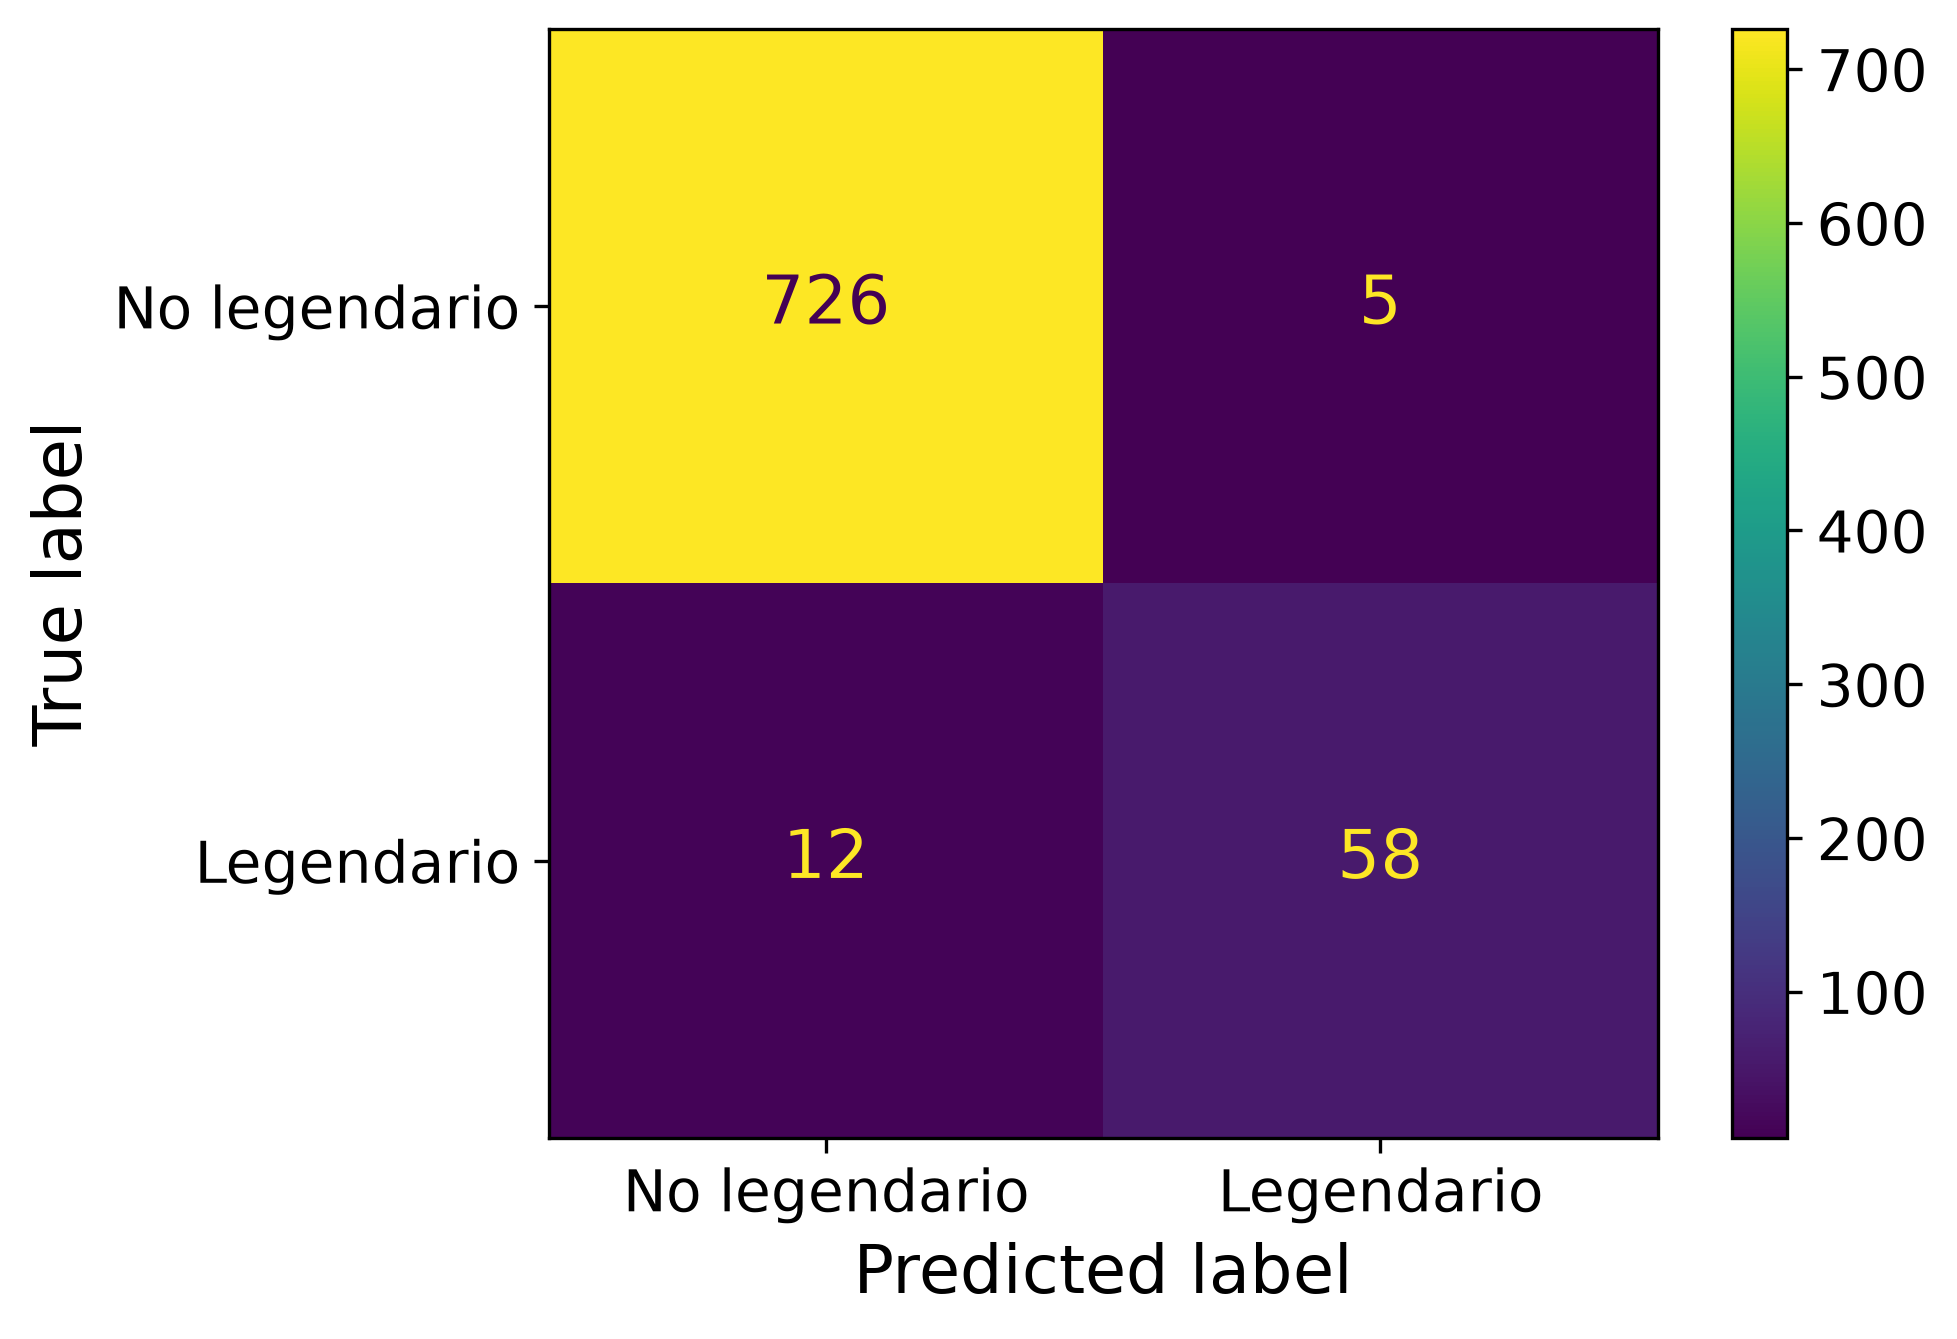

              precision    recall  f1-score   support

           0       0.98      0.99      0.99       731
           1       0.92      0.83      0.87        70

    accuracy                           0.98       801
   macro avg       0.95      0.91      0.93       801
weighted avg       0.98      0.98      0.98       801



In [49]:
y_pred = (y_proba > 0.5).astype(int)

metrics.ConfusionMatrixDisplay.from_predictions(target, y_pred, display_labels=['No legendario', 'Legendario'])
plt.show()
print(metrics.classification_report(target, y_pred))

El modelo final obtiene un Recall del 83% (con 12 legendarios que no fueron bien detectados de los 70) y una precisión del 92% (5 pokemones no legendarios mal predichos), consiguiendo un F1 del 87%. El valor del accuracy es de 98%, pero como ya fue mencionado antes, no es una métrica de la cual podamos confiar. Sin embargo, con los resultados obtenidos podemos decir que el modelo alcanza a adaptarse bien con las predicciones, aunque dependiendo principalmente del feature "base_happiness".

## Experimento: eliminar base_happiness

### Predicción

base_happiness concentra más de la mitad de la importancia del modelo, de la tarea anterior vimos que la mayoría de los no legendarios tiene un valor de 70, mientras que los legendarios pueden tomar otros valores. Se espera que al eliminar este feature del modelo, este pierda su principal criterio para separar, por lo que la métrica recall en test debería de bajar considerablemente, es decir, dejaría de detectar varios legendarios. Esperamos también que el valor de precisión baje, pues con solo features de stats el modelo sería más propenso a cometer errores de forma general, por ende disminuiría F1. Por otra parte, el accuracy debería mantenerse cerca del mismo valor, pues debido al desbalance de clases esperamos que siga habiendo una gran cantidad de predicciones de no legendarios correcta. 
En entrenamiento se espera que el F1 siga alto, porque un modelo de Random Forest sin límite de profundidad puede memorizar los datos de entrenamiento perfectamente. Esperamos que aumente la brecha entre train y test.

In [50]:
features_exp = features.drop(columns='base_happiness')

rf_exp = RandomForestClassifier(n_estimators=500, oob_score=True,
                                n_jobs=-1, random_state=42, **mejores_params)
rf_exp.fit(features_exp, target)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",500
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_true, y_pred)` to use acustom metric. Only available if `bootstrap=True`.For an illustration of out-of-bag (OOB) error estimation, see the example:ref:`sphx_glr_auto_examples_ensemble_plot_ensemble_oob.py`.",True
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Be

In [51]:
def resumen(modelo, X):
    pred_train = modelo.predict(X)
    pred_oob = (modelo.oob_decision_function_[:, 1] > 0.5).astype(int)
    return pd.DataFrame({
        'f1':        [f1_score(target, pred_train),        f1_score(target, pred_oob)],
        'precision': [precision_score(target, pred_train), precision_score(target, pred_oob)],
        'recall':    [recall_score(target, pred_train),    recall_score(target, pred_oob)]
    }, index=['train', 'test (OOB)'])

resultados_base = resumen(rf, features)
resultados_exp = resumen(rf_exp, features_exp)

pd.concat({'Con base_happiness': resultados_base,
           'Sin base_happiness': resultados_exp}).round(3)

f1  precision  recall
Con base_happiness train       1.000      1.000   1.000
                   test (OOB)  0.872      0.921   0.829
Sin base_happiness train       1.000      1.000   1.000
                   test (OOB)  0.574      0.816   0.443

In [52]:
importancias_exp = pd.Series(rf_exp.feature_importances_,
                             index=features_exp.columns).sort_values(ascending=False)
importancias_exp.head(5)

weight_kg    0.171343
speed        0.162974
sp_attack    0.151529
height_m     0.101921
hp           0.093244
dtype: float64

Como se observa, la distribución de importancia en los features ahora es más equilibrada que antes, por lo que esta vez no contamos con un feature dominante que determine la mayor parte del modelo final.

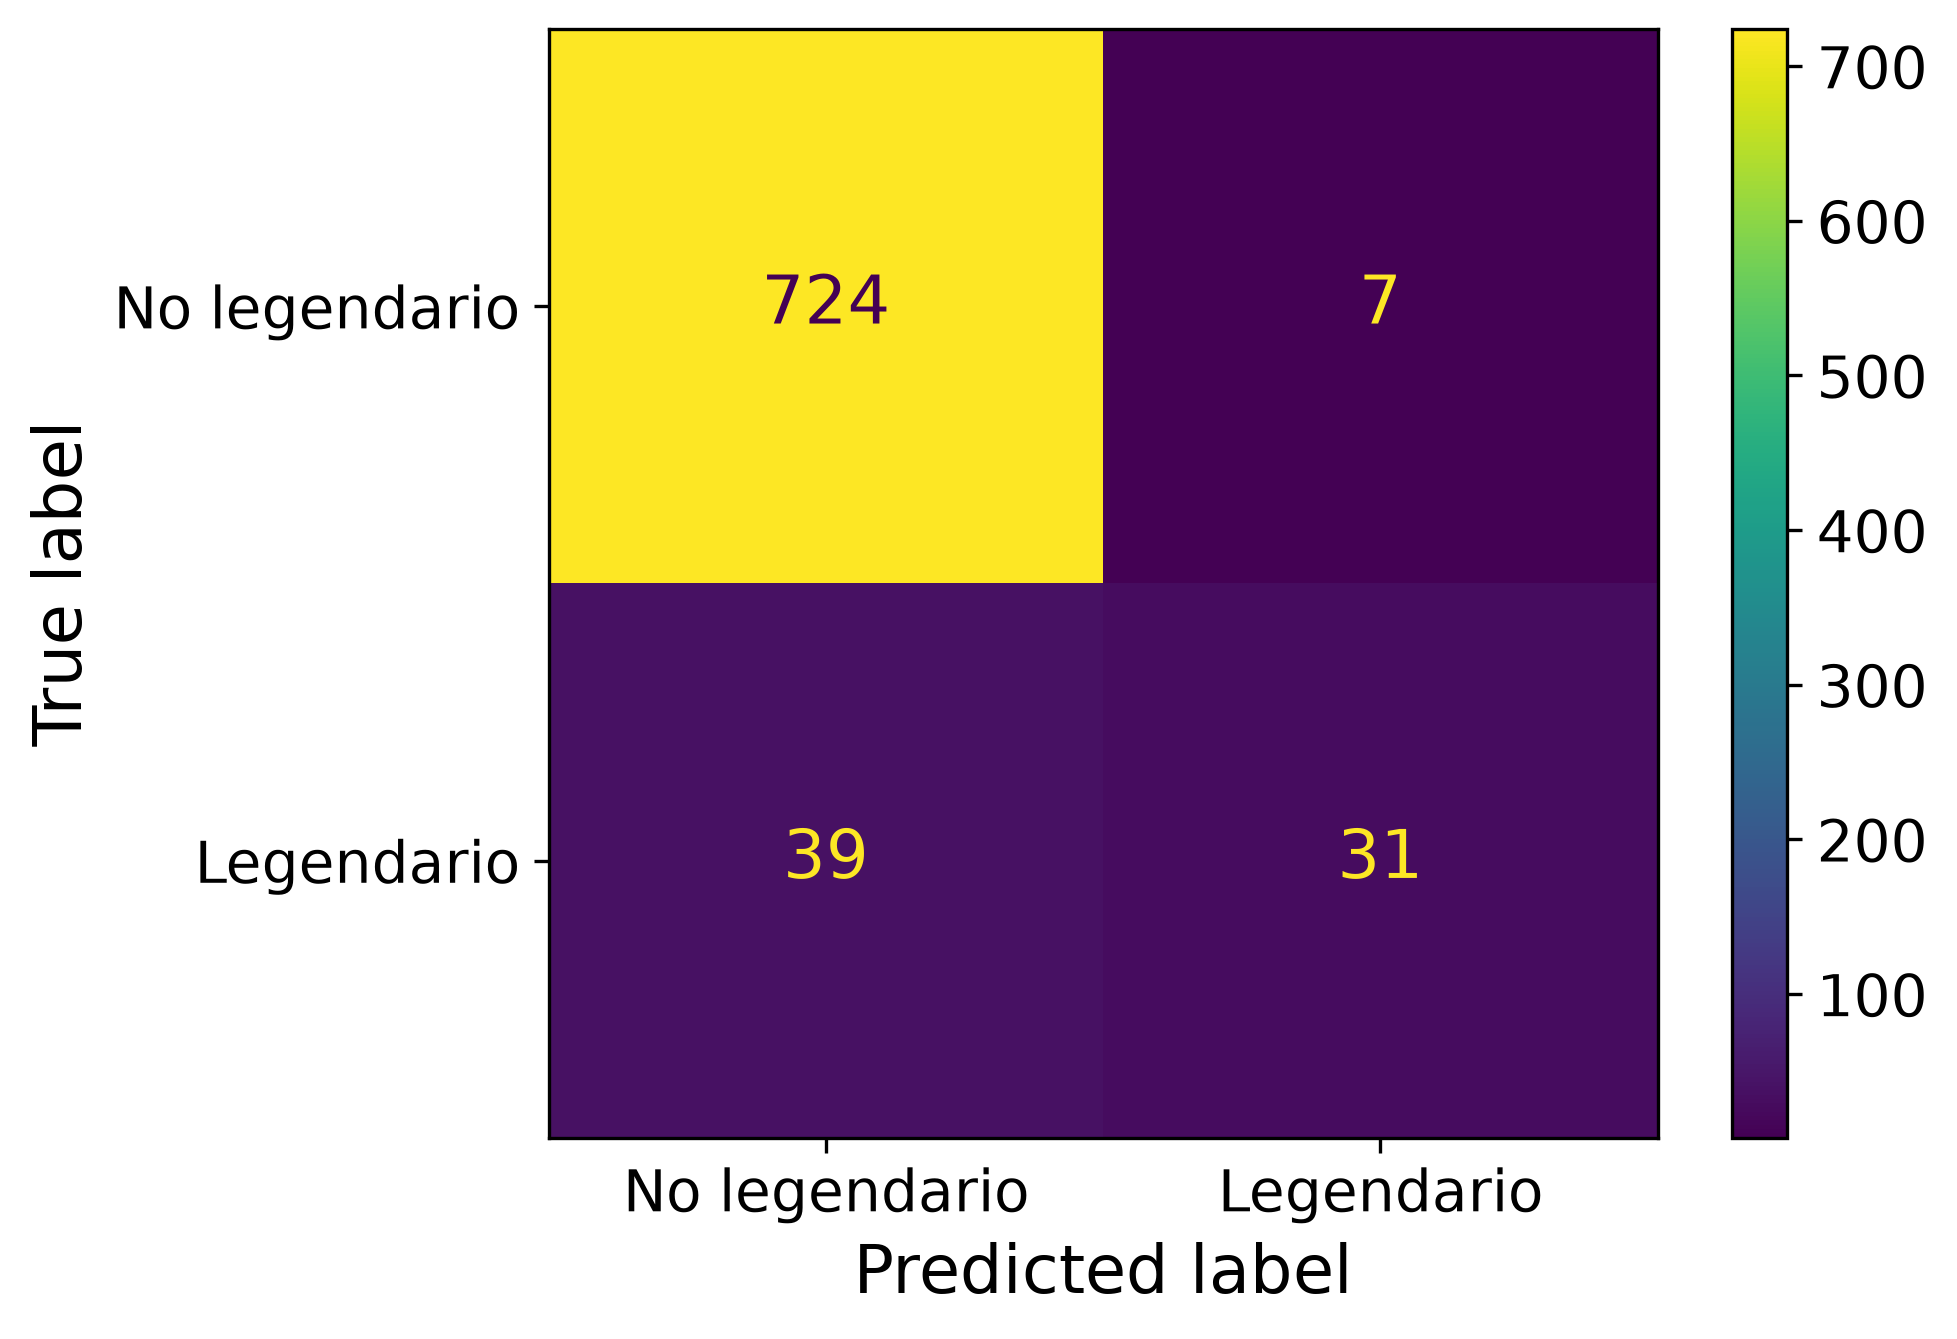

              precision    recall  f1-score   support

           0       0.95      0.99      0.97       731
           1       0.82      0.44      0.57        70

    accuracy                           0.94       801
   macro avg       0.88      0.72      0.77       801
weighted avg       0.94      0.94      0.93       801



In [53]:
y_pred_exp = (rf_exp.oob_decision_function_[:, 1] > 0.5).astype(int)

metrics.ConfusionMatrixDisplay.from_predictions(target, y_pred_exp, display_labels=['No legendario', 'Legendario'])
plt.show()
print(metrics.classification_report(target, y_pred_exp))

### Interpretación

La predicción que planteamos se cumplió. Sin base_happiness, el recall en test baja de 0.83 a 0.44, el modelo pasó de detectar 58 a detectar 31 de 70 legendarios. El F1 cae a 0.57, y la precisión a 0.82, mientras que el accuracy se sigue manteniendo alto debido al desbalance de clases mencionado. El modelo se volvió más conservador, ya que predice menos legendarios pero sigue acertando en los que predice. Además, vemos que la brecha en F1 si aumento, pues mientras se mantiene en 1.00 para el train score, decae de 0.87 a 0.57 en el test_score.

Para el caso de sin base_happiness, las features más importantes pasan a ser weight_kg, speed y sp_attack, pero los stats por sí solos no bastan, ya que muchos legendarios tienen stats parecidos a pokémon no legendarios. Esto muestra que gran parte del desempeño del modelo depende de un atributo de diseño del juego más que de características físicas del pokémon, al igual que las 5 features que eliminamos al inicio, como así también de la felicidad base.

## Auditoría del Modelo

In [ ]:
nombres = pd.read_csv('pokemon.csv')['name']
errores = features.assign(nombre=nombres, real=target, proba=y_proba)[y_pred != target]
errores.sort_values('proba')[['nombre', 'real', 'proba', 'base_happiness', 'weight_kg', 'speed', 'sp_attack']]

,nombre,real,proba,base_happiness,weight_kg,speed,sp_attack
489,Manaphy,1,0.005682,70,1.4,100,100
785,Tapu Lele,1,0.068182,70,18.6,95,130
787,Tapu Fini,1,0.072539,70,21.2,85,95
784,Tapu Koko,1,0.168367,70,20.5,130,95
786,Tapu Bulu,1,0.180791,70,45.5,75,85
718,Diancie,1,0.365591,70,8.8,110,160
646,Keldeo,1,0.382653,35,48.5,108,129
143,Articuno,1,0.410256,35,55.4,85,95
376,Regirock,1,0.410714,35,230.0,50,50
144,Zapdos,1,0.459459,35,52.6,100,125


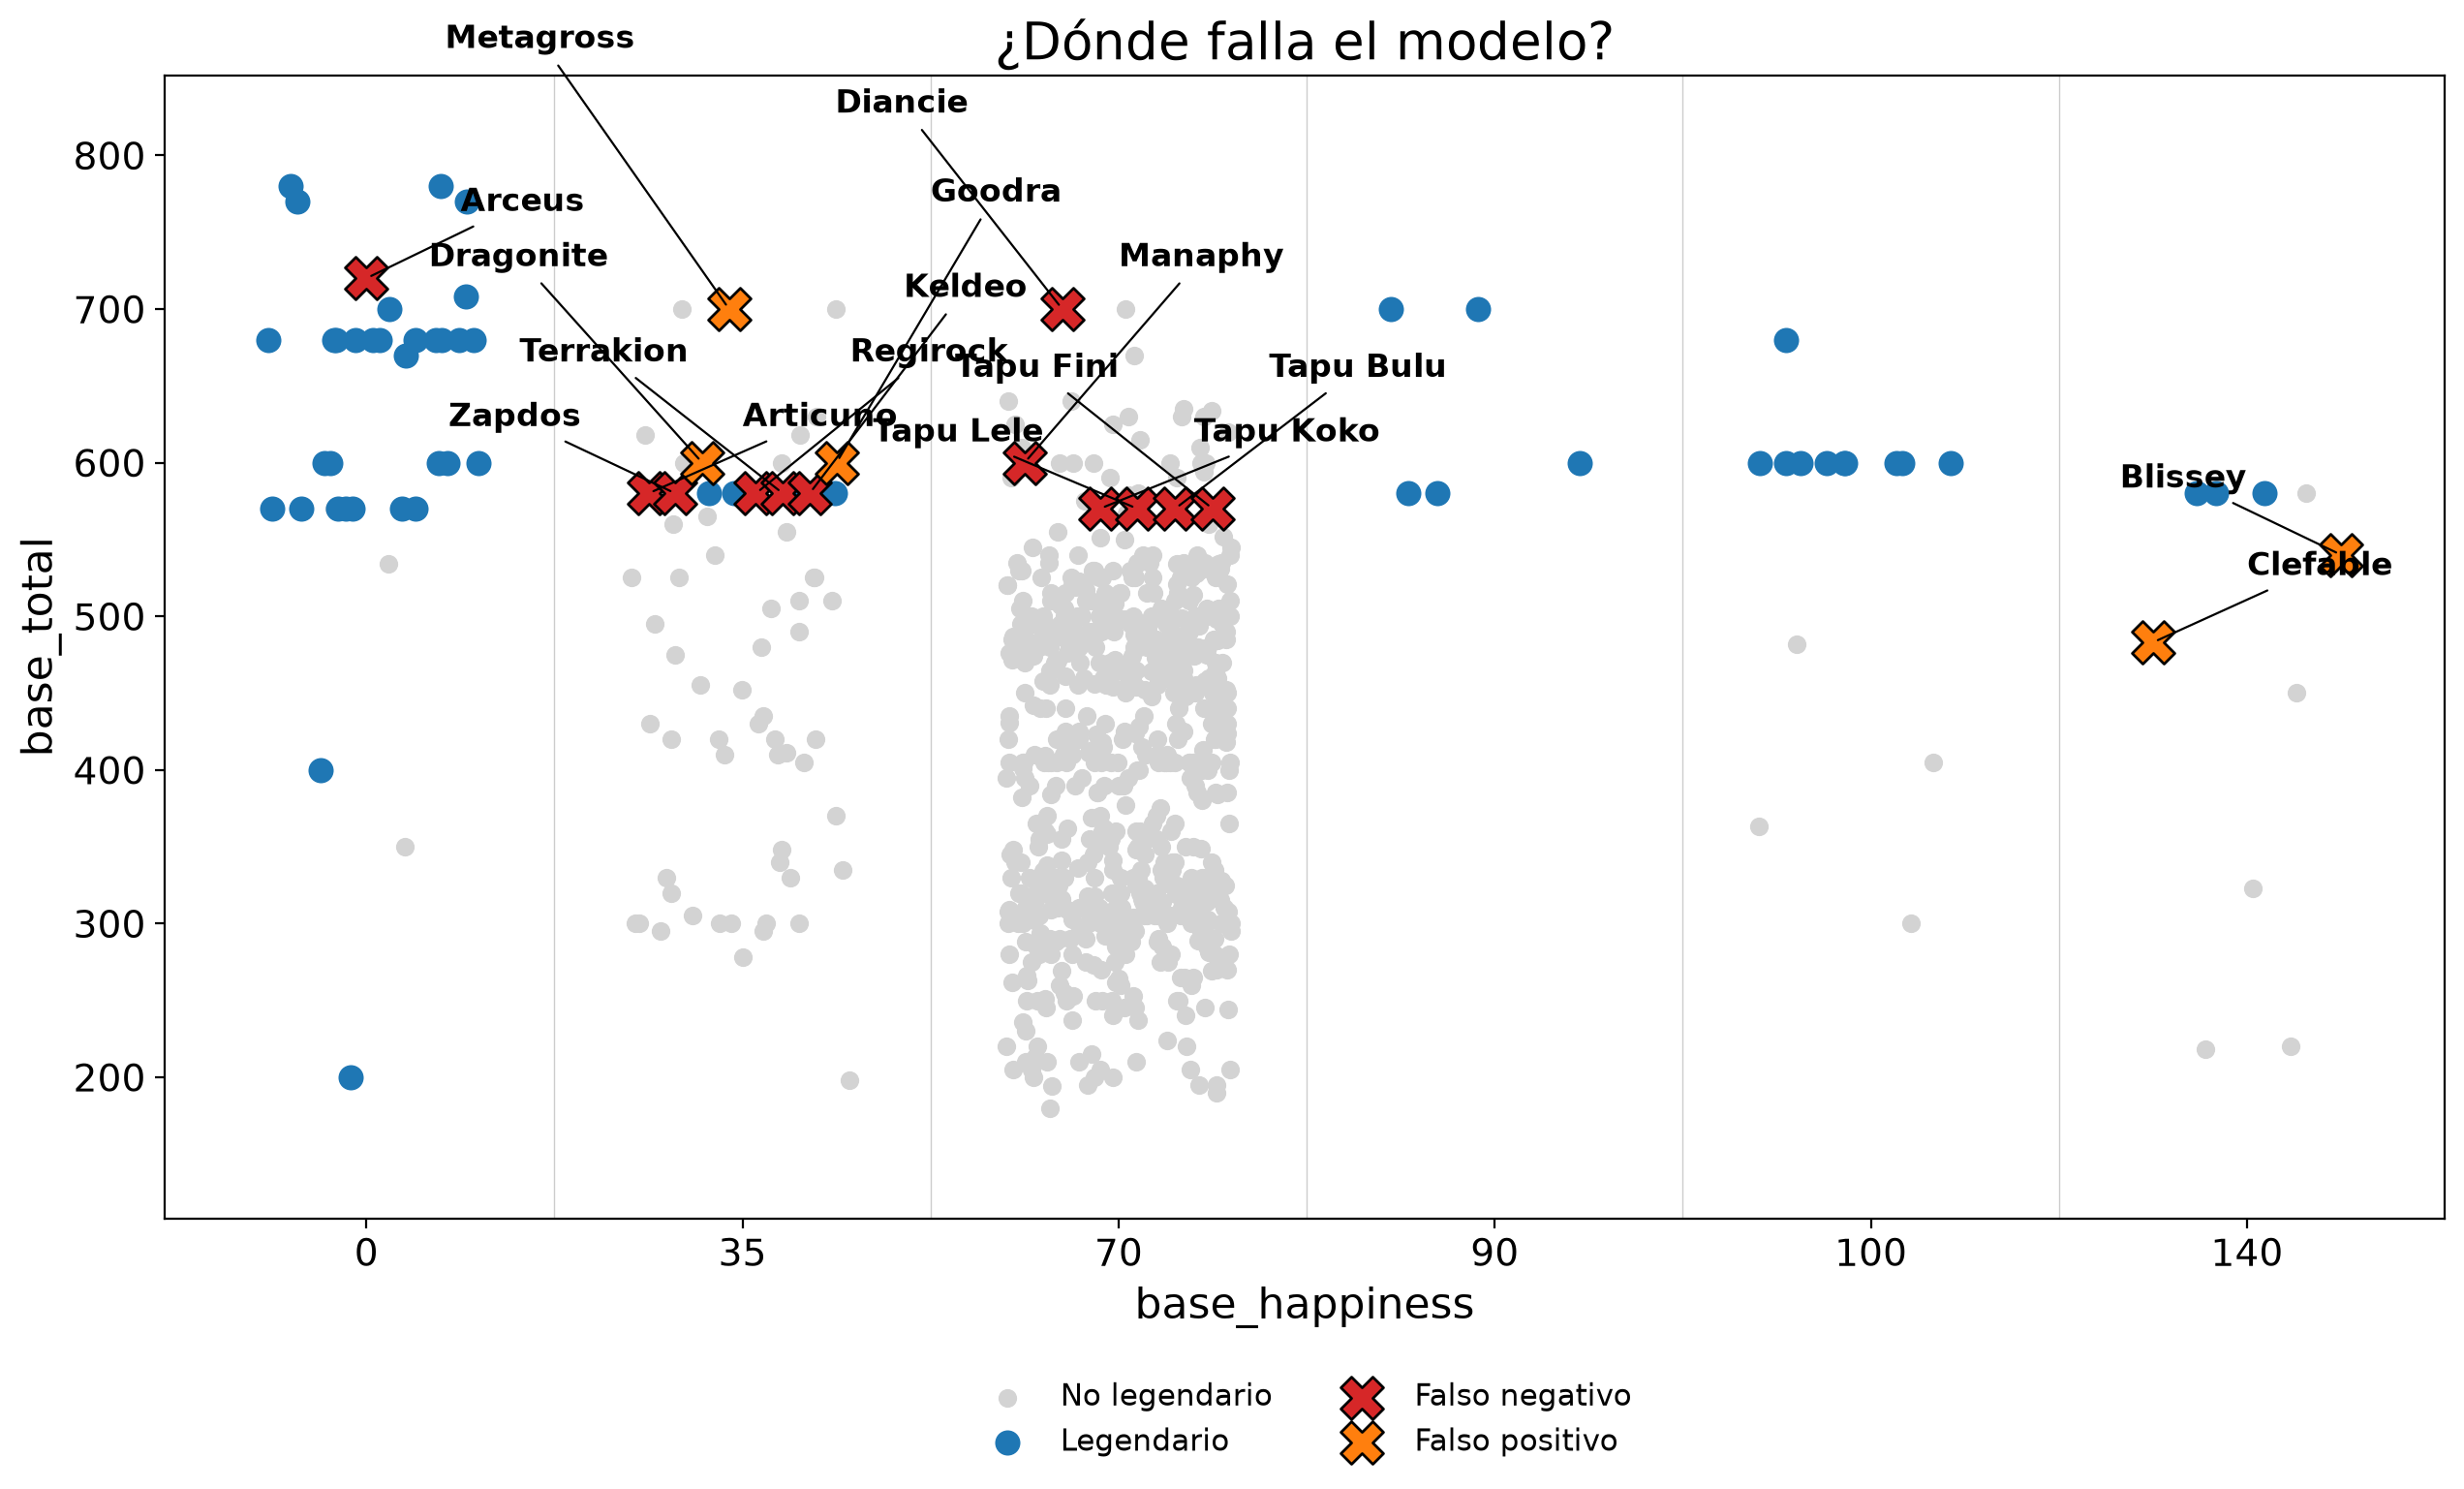

In [61]:
datos_originales = pd.read_csv('pokemon.csv')
test_info = datos_originales[['name', 'base_total', 'base_happiness']].copy()
test_info['real'] = target.values
test_info['pred'] = y_pred

valores = sorted(test_info['base_happiness'].unique())
posicion = {v: i for i, v in enumerate(valores)}
rng = np.random.default_rng(0)
test_info['x'] = test_info['base_happiness'].map(posicion) + rng.uniform(-0.3, 0.3, len(test_info))

es_error = test_info['real'] != test_info['pred']
for v, grupo in test_info[es_error].groupby('base_happiness'):
    if len(grupo) > 1:
        test_info.loc[grupo.index, 'x'] = posicion[v] + np.linspace(-0.25, 0.25, len(grupo))
    else:
        test_info.loc[grupo.index, 'x'] = posicion[v]

ok_no = test_info[(test_info['real'] == 0) & (test_info['pred'] == 0)]
ok_si = test_info[(test_info['real'] == 1) & (test_info['pred'] == 1)]
fp = test_info[(test_info['real'] == 0) & (test_info['pred'] == 1)]
fn = test_info[(test_info['real'] == 1) & (test_info['pred'] == 0)]

fig, ax = plt.subplots(figsize=(13, 8))
ax.scatter(ok_no['x'], ok_no['base_total'], c='lightgray', s=35, label='No legendario')
ax.scatter(ok_si['x'], ok_si['base_total'], c='tab:blue', s=70, label='Legendario')
ax.scatter(fn['x'], fn['base_total'], c='tab:red', marker='X', s=250, edgecolors='black',
           label='Falso negativo')
ax.scatter(fp['x'], fp['base_total'], c='tab:orange', marker='X', s=250, edgecolors='black',
           label='Falso positivo')

df_err = pd.concat([fn, fp]).sort_values(['base_happiness', 'base_total'])
df_err['k'] = df_err.groupby('base_happiness').cumcount()
for _, fila in df_err.iterrows():
    lado = 1 if fila['k'] % 2 == 0 else -1
    ax.annotate(fila['name'], (fila['x'], fila['base_total']),
                xytext=(35 * lado, 25 + 24 * (fila['k'] // 2)), textcoords='offset points',
                ha='left' if lado == 1 else 'right',
                fontsize=12, fontweight='bold',
                arrowprops=dict(arrowstyle='-', color='black', lw=0.8))
ax.margins(y=0.12)

for i in range(len(valores) - 1):
    ax.axvline(i + 0.5, color='gray', linewidth=0.5, alpha=0.4)

ax.set_xticks(range(len(valores)))
ax.set_xticklabels(valores)
ax.set_xlabel('base_happiness')
ax.set_ylabel('base_total')
ax.set_title('¿Dónde falla el modelo?')
ax.legend(fontsize=11, loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
plt.tight_layout()
plt.show()

### 1. ¿Qué tan bien generaliza el modelo?

Hay un claro sobreajuste que puede verse en F1 con 1 en entrenamiento para ambos casos, y 0.87 en test del modelo completo (con base_happiness), mientras que en el modelo experimental es 0.57. El modelo Random Forest al no tener límite de profundidad memoriza el conjunto de entrenamiento, por lo que el desempeño en train no es revelador. Aún así, el desempeño en test es considerable y predice correctamente un gran porcentaje de legendarios, lo que indica que el modelo sí aprendió patrones. En el caso del modelo sin base_happiness notamos que al modelo se le complica un poco más determinar correctamente los legendarios, prediciendo correctamente menos de la mitad de ellos. Esto es de esperar, pues no tenemos features fuertes que logren identificar bien a los legendarios, dependiendo principalmente de sus stats especiales, velocidad y la tendencia a mayor peso que existe en weight_kg.

### 2. ¿Dónde falla el modelo?

El modelo con base_happiness comete 17 errores: 12 falsos negativos (legendarios no detectados) y 5 falsos positivos (no legendarios clasificados como legendarios). Casi todos ocurren en pokemones cuyo valor de base_happiness es poco típico de su clase, y varios quedaron muy cerca del umbral de 0.5.

**Falsos negativos**
- **Happiness 70** (Manaphy, Tapu Lele, Tapu Fini, Tapu Koko, Tapu Bulu y Diancie): tienen el valor típico de los no legendarios, por lo que el modelo pierde su principal señal. Son los errores más claros, con probabilidades de ser legendario entre 0.01 y 0.37, y sus stats son altos pero no lo suficiente para compensar.
- **Happiness 35** (Keldeo, Articuno, Regirock, Zapdos y Terrakion): es un valor que comparten legendarios y no legendarios, por lo que el modelo duda, con probabilidades entre 0.38 y 0.47, es decir, cerca del umbral. Regirock, por ejemplo, tiene speed y sp_attack bajos (50 y 50), parecidos a los de pokemones defensivos no legendarios.
- **Arceus** (happiness 0): su probabilidad es exactamente 0.50, y se cuenta como error solo porque el criterio de clasificación es estrictamente mayor a 0.5, por lo que es un caso límite.

**Falsos positivos**
- **Blissey y Clefable** (happiness 140): no son legendarios, pero tienen una felicidad muy poco común. Como la mayoría de los no legendarios tiene 70, el modelo parece asociar valores distintos de 70 con ser legendario.
- **Metagross, Dragonite y Goodra** (happiness 35): comparten ese valor con varios legendarios y tienen stats muy altos. Dragonite y Goodra son pseudo-legendarios (base_total de 600), por lo que se parecen a los legendarios sin que exista un error en los datos. Metagross además tiene speed 110 y sp_attack 105, valores de su forma Mega, el error del dataset que vimos en el EDA. Sus probabilidades (0.54 a 0.60) están cerca del umbral.

**Patrón general:** los errores aparecen cuando base_happiness y los stats entregan señales contradictorias. Los legendarios con happiness 70 y los no legendarios con happiness 140 son errores "seguros", causados por el valor atípico de esa feature, mientras que los de happiness 35 y los pseudo-legendarios son casos dudosos que están cercanos al umbral.

**Modelo sin base_happiness:** detecta 31 de 70 legendarios, por lo que deja sin detectar 39 y comete unos 7 falsos positivos (ver su matriz de confusión). La distribución de errores es más grande y difícil de determinar, pues el modelo de por si resultó ser no muy efectivo con sus predicciones.

### 3. ¿Qué aprendimos que no era evidente con una única métrica?
Un F1 de 0.87 puede considerarse aceptable pero esconde que depende casi por completo de una sola feature (60% de la importancia en base_happiness). El experimento mostró que sin ella el recall cae a menos de la mitad, y el análisis de errores mostró que la mayoría de los fallos se explican por esa misma feature (malas correlaciones debido a valores de base_happiness irregulares en legendarios y no legendarios). También evidenciamos (aunque ya lo sabíamos) que no podemos depender de una única métrica para todos los casos, pues en el caso de accuracy siempre se mostraron valores excepcionales, pero que no nos entregaban información real de la efectividad del modelo.

### 4. ¿Cómo mejoraríamos el modelo?
Una posible mejora para el modelo sin base_happiness vendría de reoptimizar los hiperparametros, pues al estar eliminando este feature, entonces los hiperparámetros del modelo cambiarían con respecto al anterior, lo que significa que no solamente hay un mal resultado debido a la mala relación entre los features y ser legendario, sino que también falta optimizar nuevamente los hiperparámetros para este nuevo dataset. 

Otra mejora (que sirve para ambos casos) vendría de modificar el umbral de clasificación fijado manualmente como 0.5 en el modelo, o modificar el class_weight para penalizar más los falsos negativos, lo que disminuiría el resultado de precisión, compensando por un aumento de recall.

_Nota1: Una forma de mejorar el modelo es corregir los errores en los stats de los pokemones que poseen megaevoluciones o variaciones, de modo que no exista esta inflación en los stats de algunos pokemones no legendarios que serían detectados como tal._

_Nota2: Otra mejora evidente vendría de utilizar todos los features, lo que se provará en el anexo más adelante._

## Conclusiones

El objetivo de este trabajo era determinar si los stats de combate y algunas características simples de los pokémon bastan para predecir si un pokémon es legendario. La respuesta es que lo logran solo parcialmente, y principalmente gracias a base_happiness. El modelo final obtuvo un F1 de 0.87 (presicion 0.92, recall 0.83), pero esa feature concentra cerca del 60% de la importancia. Al eliminarla, el F1 cae a 0.57 y el recall a 0.44, por lo que el modelo deja de detectar más de la mitad de los legendarios. Esto muestra que los stats por sí solos no son suficientes, ya que muchos legendarios tienen stats similares a los de pokémon fuertes no legendarios, como los pseudo legendarios.

Debido al desbalance de clases, el accuracy no fue una métrica útil, ambos modelos superaron el 94%, valores que esconden recalls de 0.83 y 0.44. Además, los dos modelos obtienen F1 = 1.0 en entrenamiento porque memorizan los datos, y la brecha con el desempeño OOB crece de 0.13 a 0.43 al quitar base_happiness, lo que indica que sin ella el modelo generaliza peor.

El análisis de errores mostró que el modelo falla cuando base_happiness y los stats entregan señales contradictorias. Ocurre con legendarios con felicidad 70, como Manaphy y los Tapu, y con no legendarios con felicidad atípica o stats muy altos, como Blissey, Dragonite o Metagross. Varios de estos casos quedaron cerca del umbral de 0.5. Por último, en el anexo se vio que al usar todas las features el modelo es casi perfecto (F1 de 0.99), pero depende casi totalmente de base_egg_steps. Esta variable es un atributo de diseño del juego que prácticamente define a un legendario, lo que justifica haberla excluido del modelo principal.

Como trabajo futuro se propone corregir los stats inflados por formas Mega, reoptimizar los hiperparámetros del modelo sin base_happiness y ajustar el umbral de decisión para mejorar el recall. En resumen, un legendario sí se puede distinguir, pero lo que más lo determina son decisiones de diseño del juego y no sus stats de combate.

## Anexo

In [63]:
tipos = (pd.get_dummies(PokemonSet['type1'], dtype=int)
           .add(pd.get_dummies(PokemonSet['type2'], dtype=int), fill_value=0)
           .astype(int)
           .add_prefix('tipo_'))

PokemonSet = pd.concat([PokemonSet.drop(columns=['type1', 'type2']), tipos], axis=1)

In [64]:
PokemonSet

,attack,base_egg_steps,base_happiness,base_total,capture_rate,defense,experience_growth,height_m,hp,percentage_male,sp_attack,sp_defense,speed,weight_kg,generation,tipo_bug,tipo_dark,tipo_dragon,tipo_electric,tipo_fairy,tipo_fighting,tipo_fire,tipo_flying,tipo_ghost,tipo_grass,tipo_ground,tipo_ice,tipo_normal,tipo_poison,tipo_psychic,tipo_rock,tipo_steel,tipo_water
0,49,5120,70,318,45,49,1059860,0.7,45,88.1,65,65,45,6.9,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0
1,62,5120,70,405,45,63,1059860,1.0,60,88.1,80,80,60,13.0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0
2,100,5120,70,625,45,123,1059860,2.0,80,88.1,122,120,80,100.0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0
3,52,5120,70,309,45,43,1059860,0.6,39,88.1,60,50,65,8.5,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0
4,64,5120,70,405,45,58,1059860,1.1,58,88.1,80,65,80,19.0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
796,101,30720,0,570,25,103,1250000,9.2,97,NaN,107,101,61,999.9,7,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0
797,181,30720,0,570,255,131,1250000,0.3,59,NaN,59,31,109,0.1,7,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0
798,101,30720,0,570,15,53,1250000,5.5,223,NaN,97,53,43,888.0,7,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
799,107,30720,0,600,3,101,1250000,2.4,97,NaN,127,89,79,230.0,7,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0


In [65]:
all_features = PokemonSet

In [ ]:
new_filas = []
for params in ParameterGrid(parameters):
    rf_tmp = RandomForestClassifier(n_estimators=500, oob_score=True,
                                    n_jobs=-1, random_state=42, **params)
    rf_tmp.fit(all_features, target)
    new_pred = (rf_tmp.oob_decision_function_[:, 1] > 0.5).astype(int)
    new_filas.append({**params,
                  'f1': f1_score(target, new_pred),
                  'precision': precision_score(target, new_pred),
                  'recall': recall_score(target, new_pred)})

In [ ]:
new_mejores = max(new_filas, key=lambda f: f[criterio])
new_mejores_params = {k: new_mejores[k] for k in parameters}
print(new_mejores_params)

{'max_features': None, 'min_samples_split': 2, 'min_samples_leaf': 1, 'class_weight': None}


In [68]:
new_resultados_oob = pd.DataFrame(filas).sort_values(by=criterio, ascending=False)

In [69]:
new_resultados_oob

,class_weight,max_features,min_samples_leaf,min_samples_split,f1,precision,recall
18,NaN,None,1,2,0.985915,0.972222,1.000000
4,NaN,sqrt,2,5,0.979021,0.958904,1.000000
19,NaN,None,1,5,0.979021,0.958904,1.000000
21,NaN,None,2,2,0.979021,0.958904,1.000000
22,NaN,None,2,5,0.979021,0.958904,1.000000
0,NaN,sqrt,1,2,0.978723,0.971831,0.985714
13,NaN,4,2,5,0.971831,0.958333,0.985714
5,NaN,sqrt,2,10,0.971831,0.958333,0.985714
2,NaN,sqrt,1,10,0.971831,0.958333,0.985714
9,NaN,4,1,2,0.971831,0.958333,0.985714


In [70]:
new_rf = RandomForestClassifier(n_estimators=500, oob_score=True,
                            n_jobs=-1, random_state=42, **new_mejores_params)
new_rf.fit(all_features, target)

y_proball = new_rf.oob_decision_function_[:, 1]

In [71]:
new_modelo_final = new_rf

all_importancias = pd.Series(new_modelo_final.feature_importances_, index=all_features.columns).sort_values(ascending=False)
all_importancias.head(10)

base_egg_steps    0.859083
capture_rate      0.085266
tipo_normal       0.013979
generation        0.009073
base_total        0.007396
base_happiness    0.007017
speed             0.002960
attack            0.002575
hp                0.002332
tipo_psychic      0.002226
dtype: float64

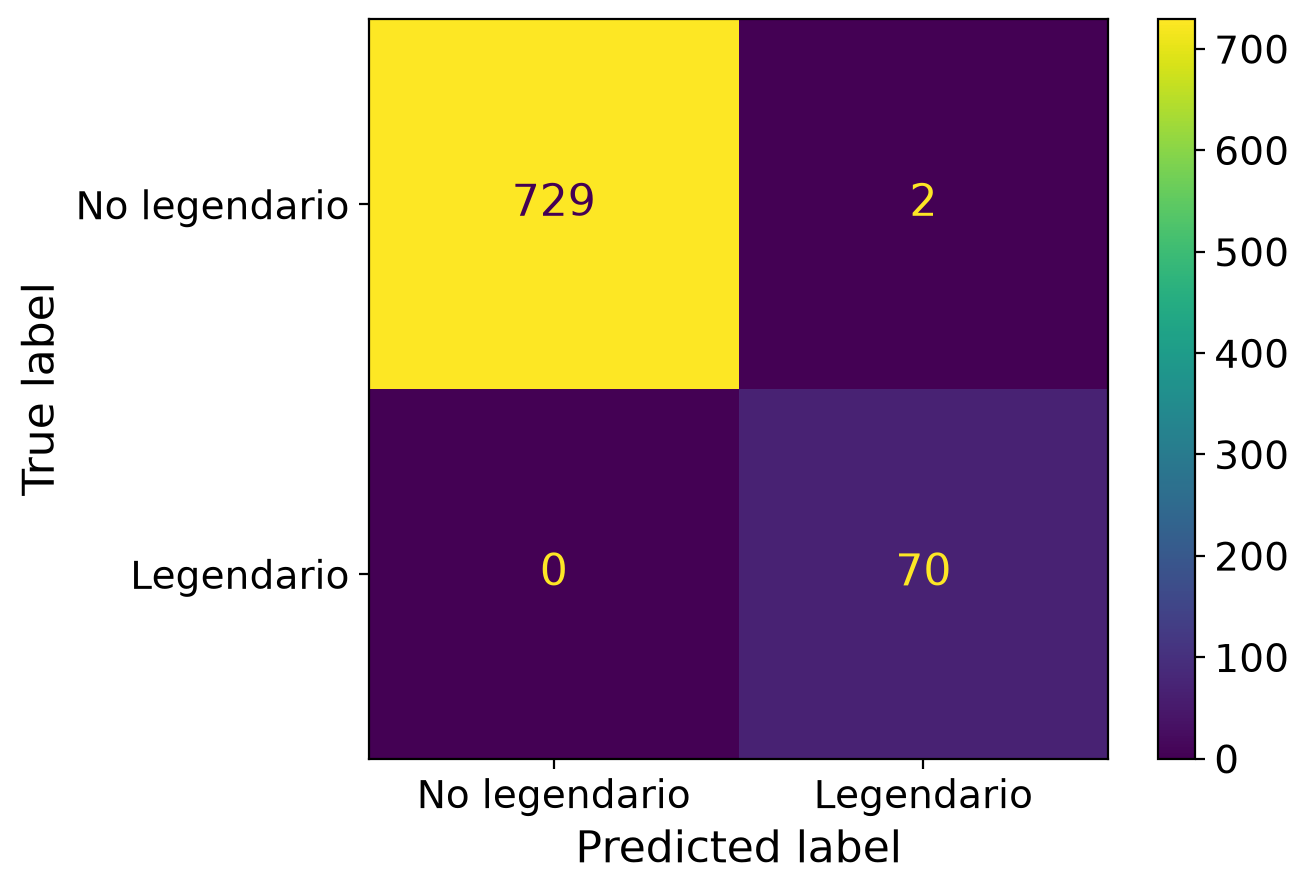

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       731
           1       0.97      1.00      0.99        70

    accuracy                           1.00       801
   macro avg       0.99      1.00      0.99       801
weighted avg       1.00      1.00      1.00       801



In [72]:
new_y_pred = (y_proball > 0.5).astype(int)

metrics.ConfusionMatrixDisplay.from_predictions(target, new_y_pred, display_labels=['No legendario', 'Legendario'])
plt.show()
print(metrics.classification_report(target, new_y_pred))

locura

In [74]:
nombres_all = pd.read_csv('pokemon.csv')['name']
errores_all = all_features.assign(nombre=nombres_all, real=target, proba=y_proba)[new_y_pred != target]
errores_all.sort_values('proba')[['nombre', 'real', 'proba', 'base_egg_steps', 'capture_rate']]

,nombre,real,proba,base_egg_steps,capture_rate
772,Silvally,0,0.485549,30720,3
375,Metagross,0,0.544910,10240,3


locuron